In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import umap

I0000 00:00:1793230083.775921  436553 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793230083.776547  436553 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793230083.829933  436553 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793230085.365036  436553 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [5]:
# Change for your data
root_path = Path("/data/smfish/20260311_bartelle_smFISH_cryo_48hr_male")

In [6]:
output_dir = root_path / "big_fish" / "results" / "all_tiles_2D"
matrix_path = output_dir / "cellxgene_matrix.csv"
# spots_path_bit5 = os.path.join(output_dir, "spots_bit_5.csv")
matrix = pd.read_csv(matrix_path, usecols= ['cell_id', 'Angpt1', 'Crmp1', 'Dcx', 'Hdac11', 'Itgam', 'Notch2',
       'Ptch1', 'Serpine1', 'Shh', 'Slc1a3', 'Tcf12', 'Tek', 'Tgfb1', 'Tgfbi', 'Aif1', 'Nnat'])
print(matrix.shape)
print(matrix.head())

(9709, 17)
   cell_id  Angpt1   Crmp1    Dcx  Hdac11  Itgam  Notch2  Ptch1  Serpine1  \
0        0    2748  119363  10559   78683  13164   10057  18360      8594   
1        1       0       1      0       0      0       0      0         0   
2        3       0       0      0       0      0       0      1         0   
3        5       0       1      0       0      0       0      3         0   
4        6       0      35      1      15      0       0      1         0   

    Shh  Slc1a3  Tcf12   Tek  Tgfb1  Tgfbi   Aif1   Nnat  
0  4103  103261   9700  8471  15820  13410  14236  13704  
1     0       1      0     0      0      0      0      0  
2     0       1      0     0      0      0      0      0  
3     0       9      0     0      0      0      0      3  
4     0       1      0     0      0      0      0      0  


# Filtering

In [7]:
# Select the columns representing gene counts
genes = matrix.columns.drop("cell_id")
# convert integer counts to floats
counts = matrix[genes].astype(float)

In [6]:
counts

,Angpt1,Crmp1,Dcx,Hdac11,Itgam,Notch2,Ptch1,Serpine1,Shh,Slc1a3,Tcf12,Tek,Tgfb1,Tgfbi,Aif1,Nnat
0,2748.0,119363.0,10559.0,78683.0,13164.0,10057.0,18360.0,8594.0,4103.0,103261.0,9700.0,8471.0,15820.0,13410.0,14236.0,13704.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,3.0
4,0.0,35.0,1.0,15.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9704,0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
9705,0.0,32.0,2.0,3.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
9706,0.0,23.0,1.0,4.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
9707,0.0,4.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
# Sum the total number of counts per cell
cell_total = counts.sum(axis=1)

In [8]:
cell_total.describe()

count      9709.000000
mean        113.743125
std        4508.222726
min           1.000000
25%          21.000000
50%          49.000000
75%          96.000000
max      444233.000000
dtype: float64

In [9]:
# Identify the cells whose total counts (across all genes) are in the top 1% (or above the 99th percentile)
cell_upper = cell_total.quantile(0.99)
high_total_cells = cell_total > cell_upper

# what is the 99th percentile of counts/cell
print(f"The 99th percentile threshold is {cell_upper}")

# How many cells will we drop?
print(f"The number of cells to be dropped is {high_total_cells.sum(axis=0)}")

The 99th percentile threshold is 290.9200000000001
The number of cells to be dropped is 98


In [10]:
# Drop those cells
filtered_counts = counts.loc[~high_total_cells]
filtered_counts.shape

(9611, 16)

In [11]:
filtered_counts.max()

Angpt1       21.0
Crmp1       174.0
Dcx          23.0
Hdac11      128.0
Itgam        54.0
Notch2       78.0
Ptch1        60.0
Serpine1    104.0
Shh          34.0
Slc1a3       94.0
Tcf12        49.0
Tek          99.0
Tgfb1        57.0
Tgfbi        82.0
Aif1         68.0
Nnat         86.0
dtype: float64

In [12]:
# Another filtering step would be to remove any cell exceeding the 99th-percentile threshold for at least one gene.
# However, the 99th percentile for each gene is in the tens for many genes. It's quite low. I'm hesitant to throw away that data.
# Also would I do this filtering on counts or filtered_counts? That would change the effect.

# gene_upper = counts.quantile(0.99, axis=0)

# high_gene_cells = counts.gt(gene_upper, axis="columns").any(axis=1)

# filtered_counts = counts.loc[~high_gene_cells]



# Another way to do it: counts = counts[counts["Aif1"] <= float(gene_upper["Aif1"])-1]

# PCA

In [11]:
# Base-2 log transformation
# the data because counts span orders of magnitude. Brings data values closer together
# gene expression data is heavily right skewed
# add the +1 so that zero counts remain valid
log_counts = np.log2(filtered_counts + 1)

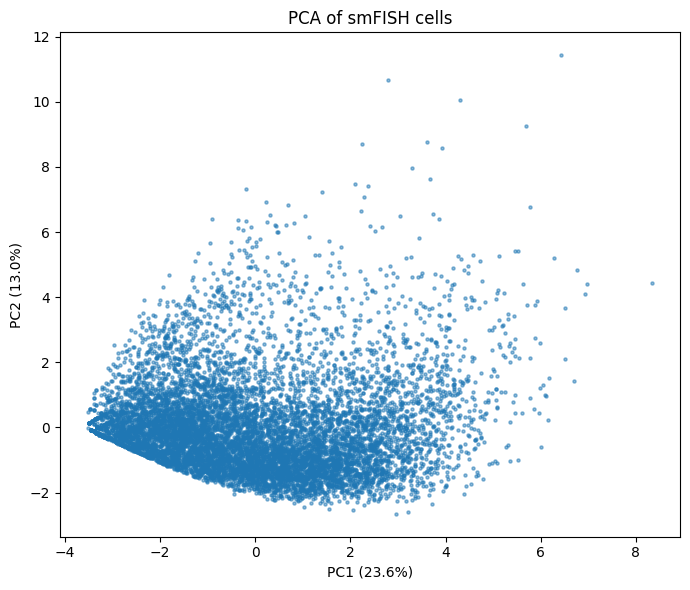

In [37]:
# Standardize genes and run PCA
scaled_counts = StandardScaler().fit_transform(log_counts)
pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled_counts)

# Plot cells in PCA space
plt.figure(figsize=(7, 6))
plt.scatter(pcs[:, 0], pcs[:, 1], s=5, alpha=0.5)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
plt.title("PCA of smFISH cells")
plt.tight_layout()
plt.show()

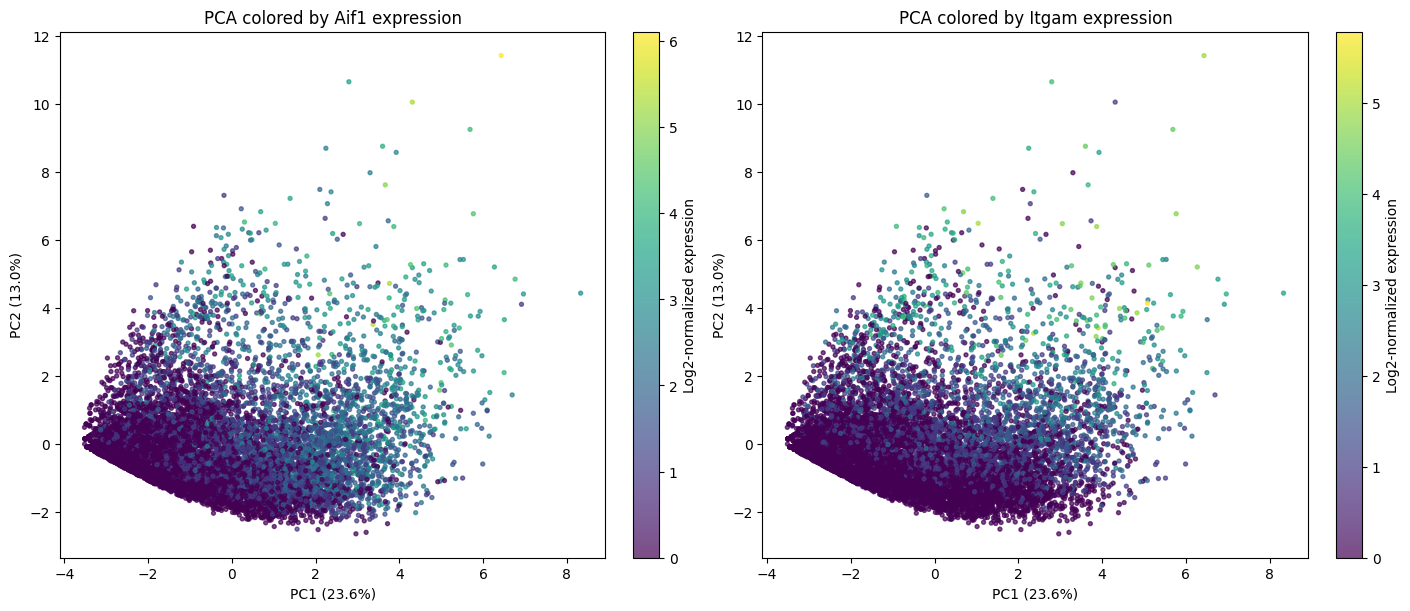

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Aif1", "Itgam"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

In [15]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# for ax, gene in zip(axes, ["Aif1", "Itgam"]):
#     expression = log_counts[gene].to_numpy()
#     positive = expression > 0

#     # Plot all cells gray first
#     ax.scatter(
#         pcs[:, 0],
#         pcs[:, 1],
#         color="lightgray",
#         s=8,
#         alpha=0.7,
#     )

#     # Overlay cells with detected expression
#     scatter = ax.scatter(
#         pcs[positive, 0],
#         pcs[positive, 1],
#         c=expression[positive],
#         cmap="viridis",
#         s=8,
#         alpha=0.7,
#     )

#     ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
#     ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
#     ax.set_title(f"PCA colored by {gene} expression")
#     fig.colorbar(scatter, ax=ax, label="Log-normalized expression")

# plt.show()

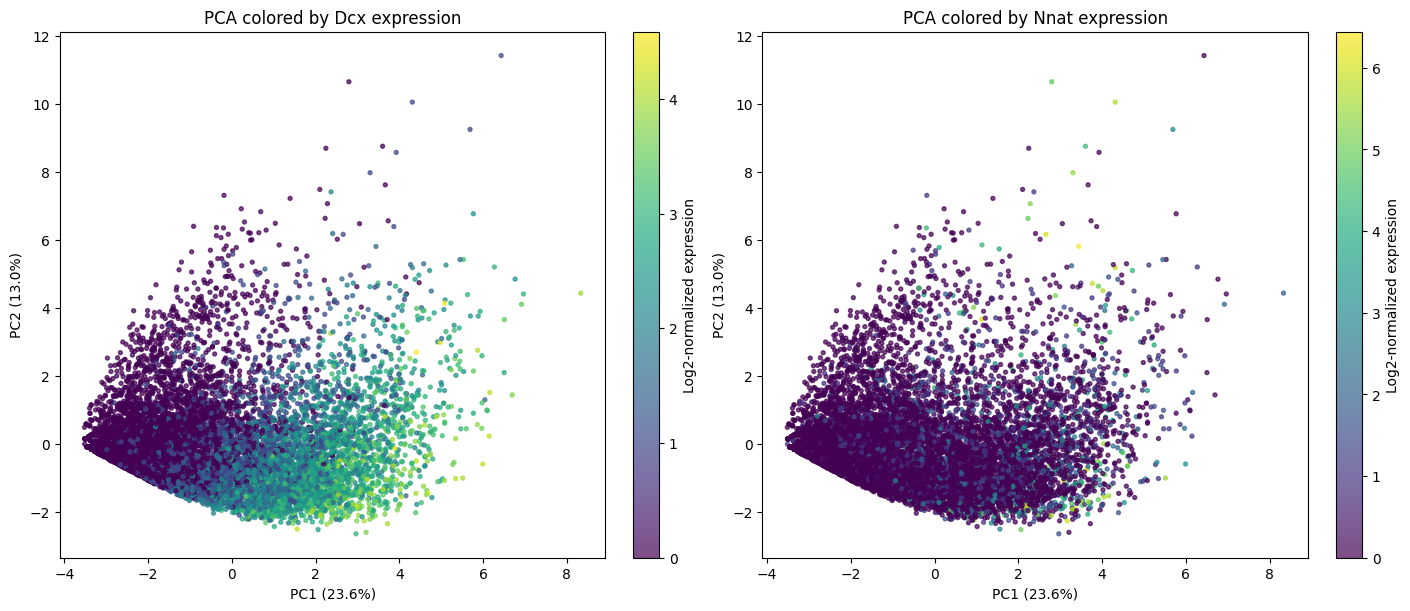

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Dcx", "Nnat"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

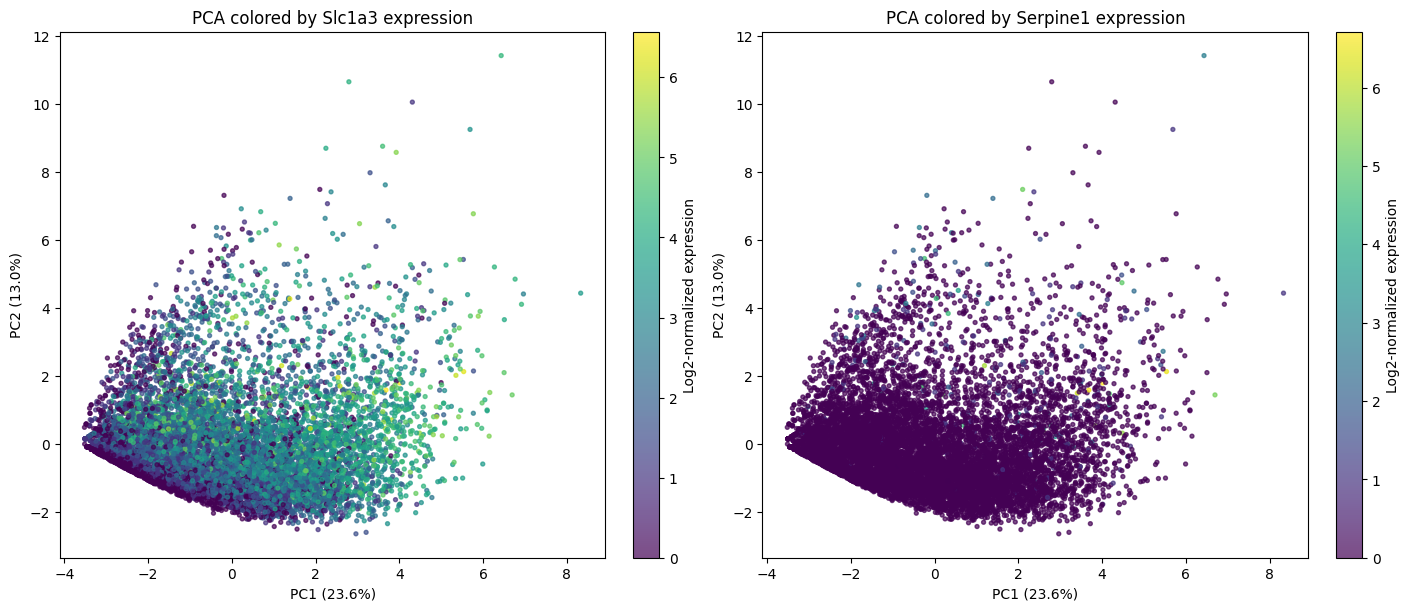

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Slc1a3", "Serpine1"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

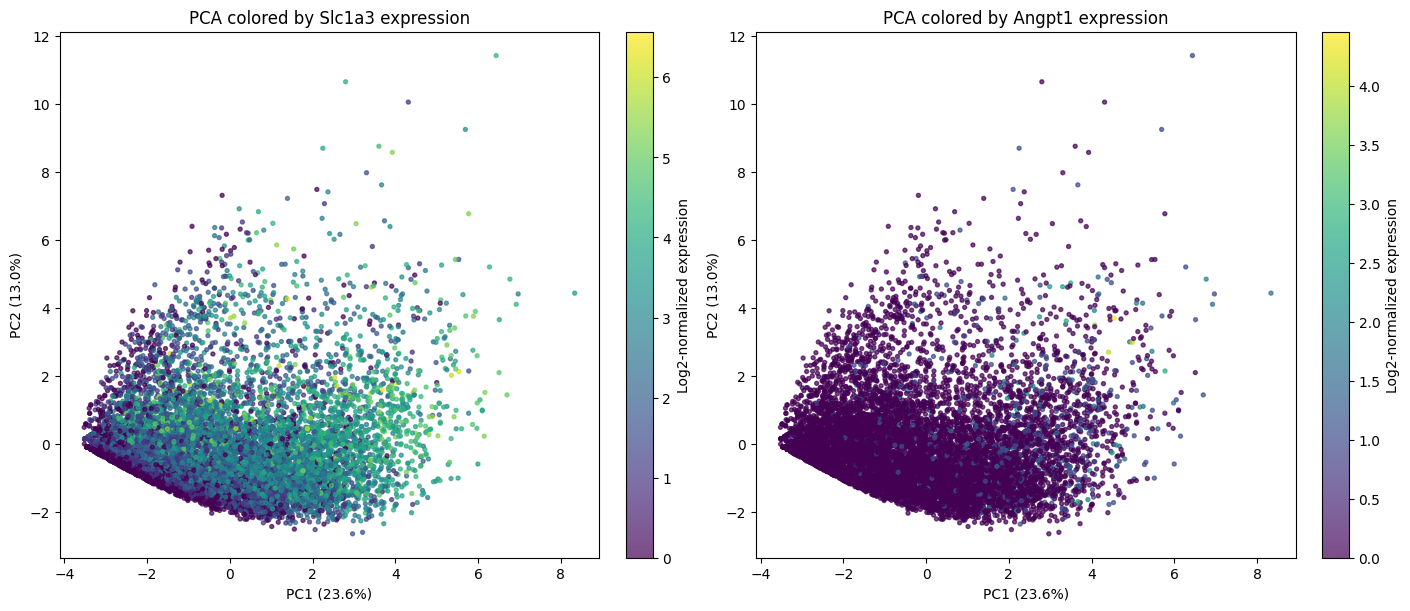

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Slc1a3", "Angpt1"]):
    scatter = ax.scatter(
        pcs[:, 0],
        pcs[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    ax.set_title(f"PCA colored by {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-normalized expression")

plt.show()

# Scatter plots

### This is the incorrect way of doing it because it contains library size normalization!!!
But it looks pretty, unfortunately.

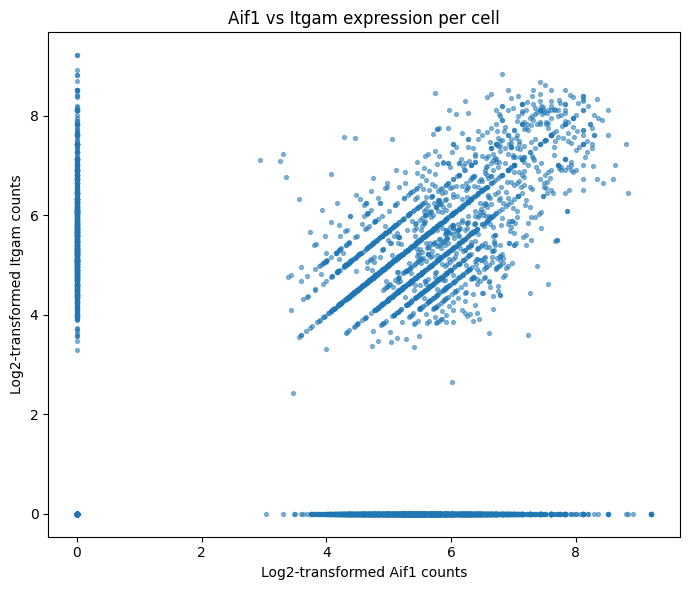

In [19]:
### This is the incorrect way of doing it because it contains library size normalization!!!

# sum the total # of spots per cell
library_size = counts.sum(axis=1).replace(0, 1)

# library size normalization, then natural-log2 transformation log(1+x)
log_counts_lsn = (counts.div(library_size, axis=0) * 1e4).apply(np.log1p)


plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts_lsn["Aif1"],
    log_counts_lsn["Itgam"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log2-transformed Aif1 counts")
plt.ylabel("Log2-transformed Itgam counts")
plt.title("Aif1 vs Itgam expression per cell")
plt.tight_layout()
plt.show()

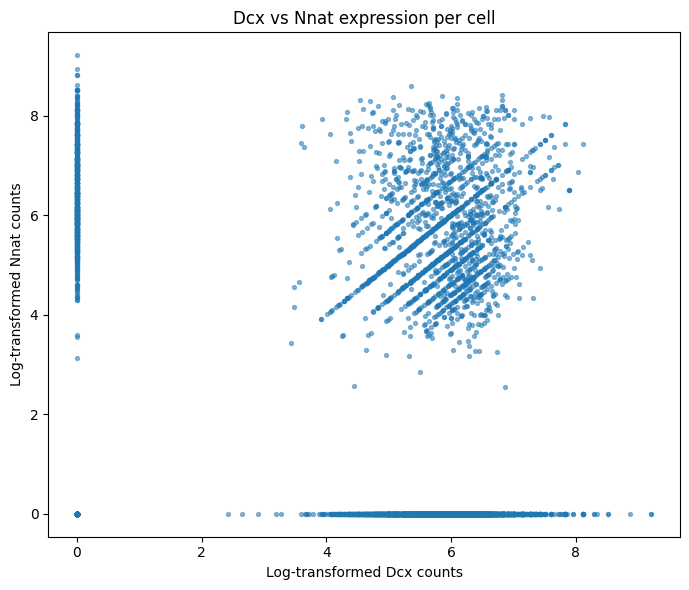

In [20]:
plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts_lsn["Dcx"],
    log_counts_lsn["Nnat"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log-transformed Dcx counts")
plt.ylabel("Log-transformed Nnat counts")
plt.title("Dcx vs Nnat expression per cell")
plt.tight_layout()
plt.show()

### Real scatter plots

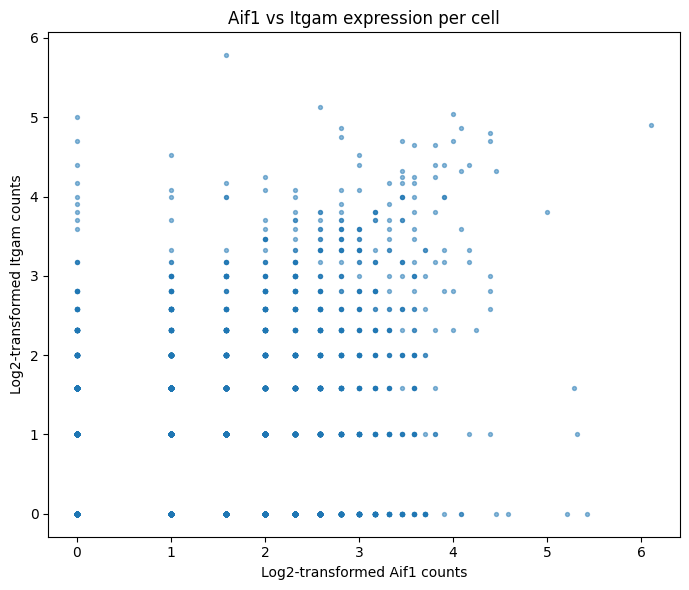

In [21]:
plt.figure(figsize=(7, 6))

plt.scatter(
    log_counts["Aif1"],
    log_counts["Itgam"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Log2-transformed Aif1 counts")
plt.ylabel("Log2-transformed Itgam counts")
plt.title("Aif1 vs Itgam expression per cell")
plt.tight_layout()
plt.show()

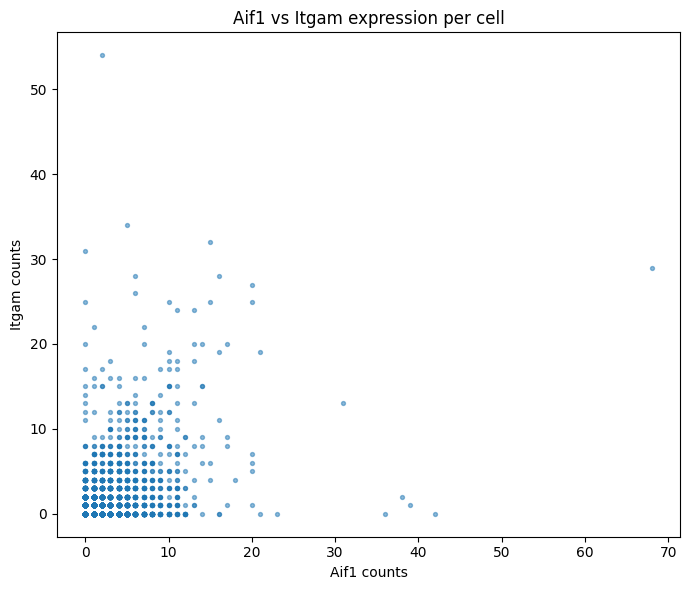

In [22]:
plt.figure(figsize=(7, 6))

plt.scatter(
    filtered_counts["Aif1"],
    filtered_counts["Itgam"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Aif1 counts")
plt.ylabel("Itgam counts")
plt.title("Aif1 vs Itgam expression per cell")
plt.tight_layout()
plt.show()

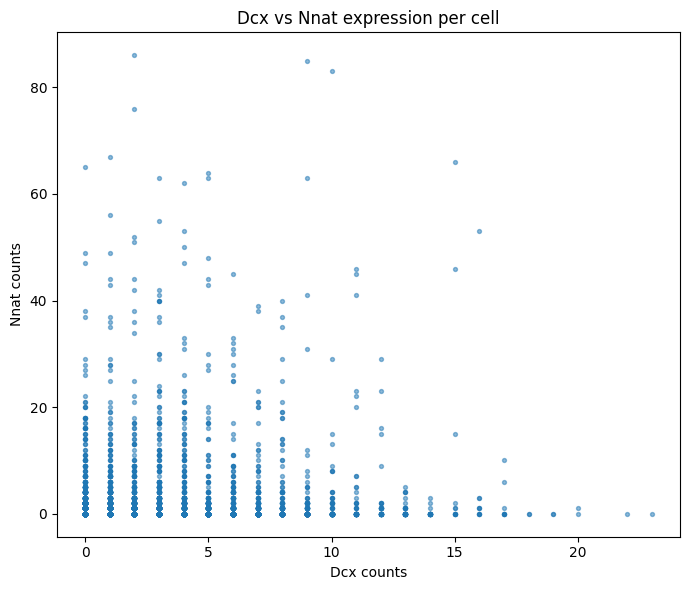

In [52]:
plt.figure(figsize=(7, 6))

plt.scatter(
    filtered_counts["Dcx"],
    filtered_counts["Nnat"],
    s=8,
    alpha=0.5,
)

plt.xlabel("Dcx counts")
plt.ylabel("Nnat counts")
plt.title("Dcx vs Nnat expression per cell")
plt.tight_layout()
plt.show()

# Elbow Plots

## Microglia

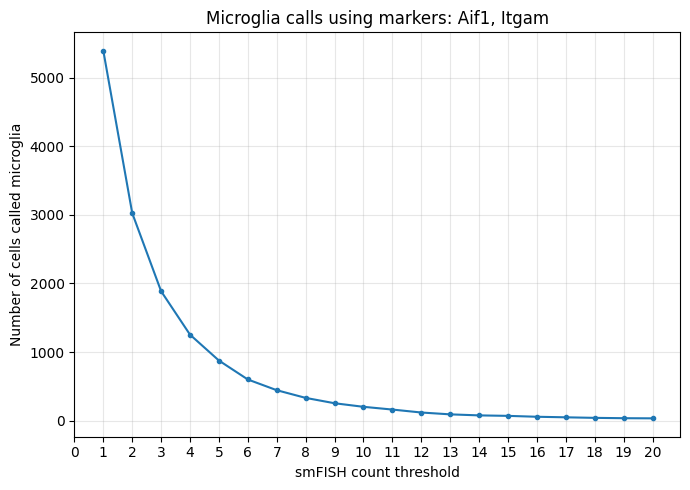

In [23]:
# Define marker genes for the cell type
marker_genes = ["Aif1", "Itgam"]

# Verify that all requested markers are available
missing_genes = set(marker_genes) - set(counts.columns)
if missing_genes:
    raise ValueError(f"Missing marker genes: {sorted(missing_genes)}")

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (filtered_counts[marker_genes] >= threshold).any(axis=1).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using markers: {', '.join(marker_genes)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

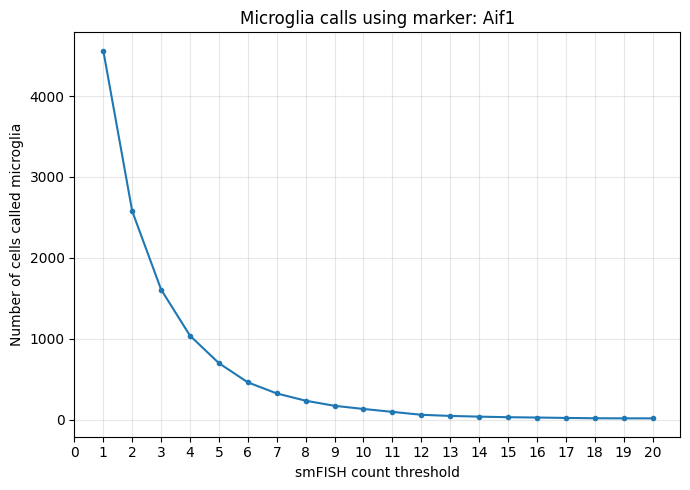

In [24]:
# Define marker genes for the cell type
marker_gene = ["Aif1"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

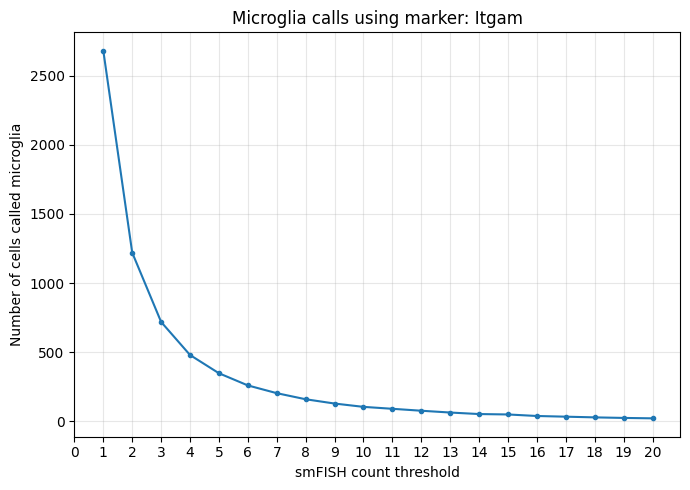

In [25]:
# Define marker genes for the cell type
marker_gene = ["Itgam"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
microglia_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, microglia_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called microglia")
plt.title(f"Microglia calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Neural Progenitors

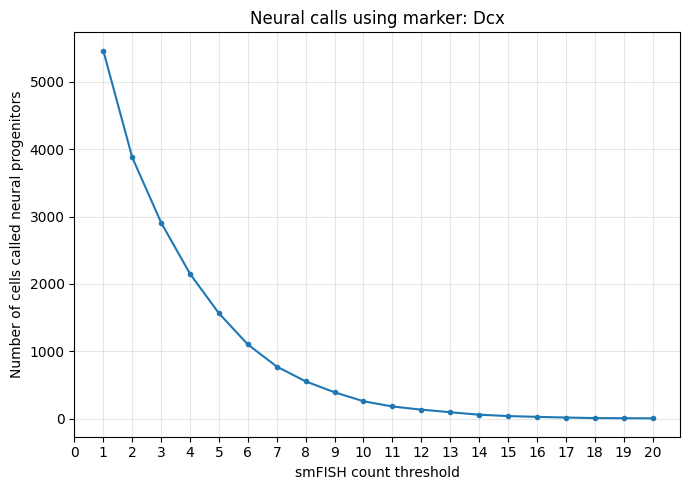

In [26]:
# Define marker genes for the cell type
marker_gene = ["Dcx"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

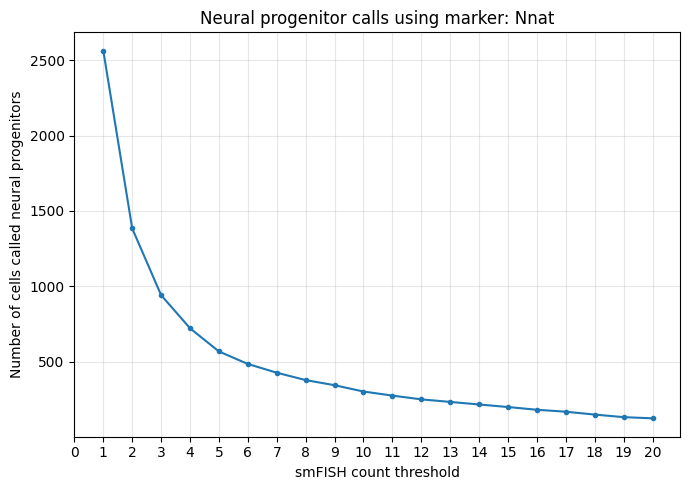

In [27]:
# Define marker genes for the cell type
marker_gene = ["Nnat"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

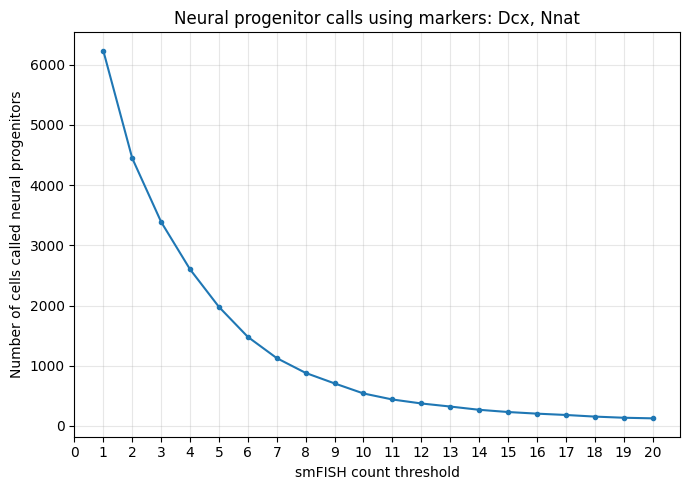

In [28]:
# Define marker genes for the cell type
marker_genes = ["Dcx", "Nnat"]

# Verify that all requested markers are available
missing_genes = set(marker_genes) - set(counts.columns)
if missing_genes:
    raise ValueError(f"Missing marker genes: {sorted(missing_genes)}")

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
np_counts = [
    (filtered_counts[marker_genes] >= threshold).any(axis=1).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, np_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called neural progenitors")
plt.title(f"Neural progenitor calls using markers: {', '.join(marker_genes)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Astrocytes

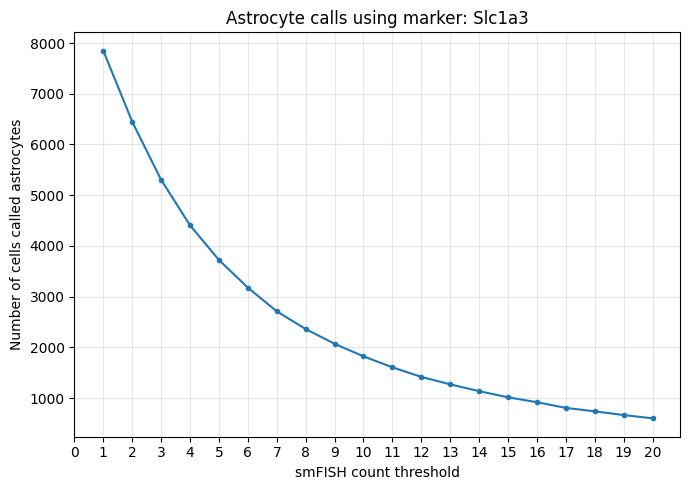

In [29]:
# Define marker genes for the cell type
marker_gene = ["Slc1a3"]

# Test thresholds from 1 through the 20
thresholds = np.arange(1, 21)

# A cell is called positive if any marker reaches the threshold
astrocyte_counts = [
    (filtered_counts[marker_gene] >= threshold).sum()
    for threshold in thresholds
]

plt.figure(figsize=(7, 5))
plt.plot(thresholds, astrocyte_counts, marker="o", markersize=3)
plt.xlabel("smFISH count threshold")
plt.xticks(range(21))
plt.ylabel("Number of cells called astrocytes")
plt.title(f"Astrocyte calls using marker: {', '.join(marker_gene)}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# UMAP

In [30]:
# if not installed
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


UMAP expects:

rows = cells

columns = genes

values = normalized/transformed expression values

PCA is linear; UMAP is nonlinear 

UMAP can produce different visual structures depending on its parameters (i.e. number of neighbors)

/home/mauri/miniforge3/envs/bigfish_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


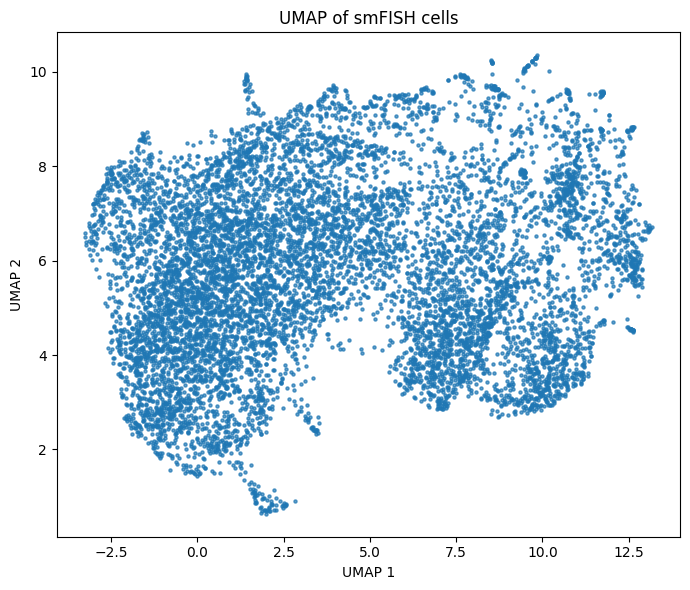

In [31]:
# Compute UMAP
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.3,
    n_components=2,
    metric="euclidean",
    random_state=42
)
# use log counts - the filtered, log2-transformed counts
embedding = reducer.fit_transform(log_counts)

# Plot
plt.figure(figsize=(7, 6))
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    s=5,
    alpha=0.7
)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP of smFISH cells")
plt.tight_layout()
plt.show()

/home/mauri/miniforge3/envs/bigfish_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


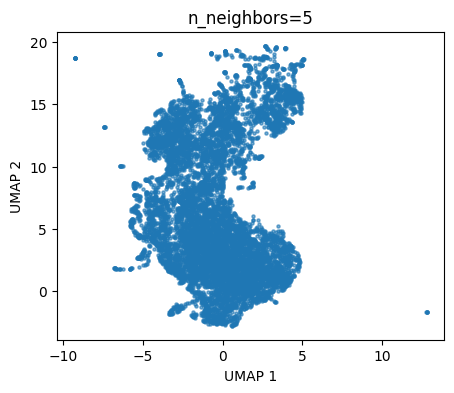

/home/mauri/miniforge3/envs/bigfish_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


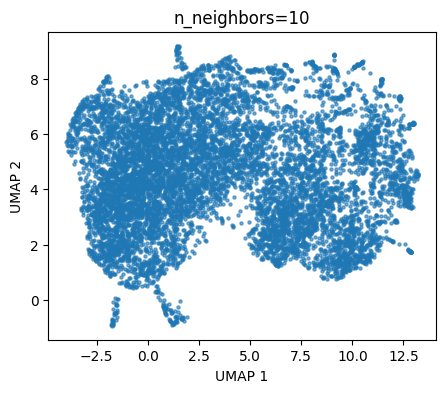

/home/mauri/miniforge3/envs/bigfish_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


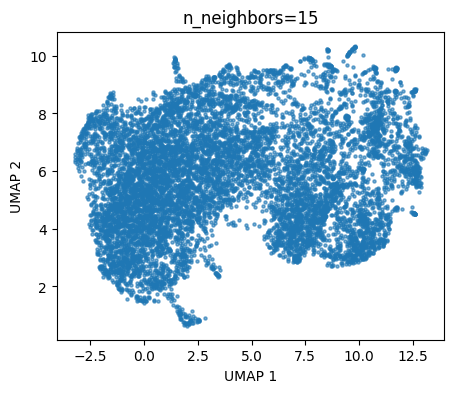

In [38]:
for n_neighbors in [5, 10, 15]:
    reducer = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=0.3,
        random_state=42
    )

    embedding = reducer.fit_transform(log_counts)

    plt.figure(figsize=(5, 4))
    plt.scatter(embedding[:, 0], embedding[:, 1], s=5, alpha=0.6)
    plt.title(f"n_neighbors={n_neighbors}")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.show()

/home/mauri/miniforge3/envs/bigfish_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


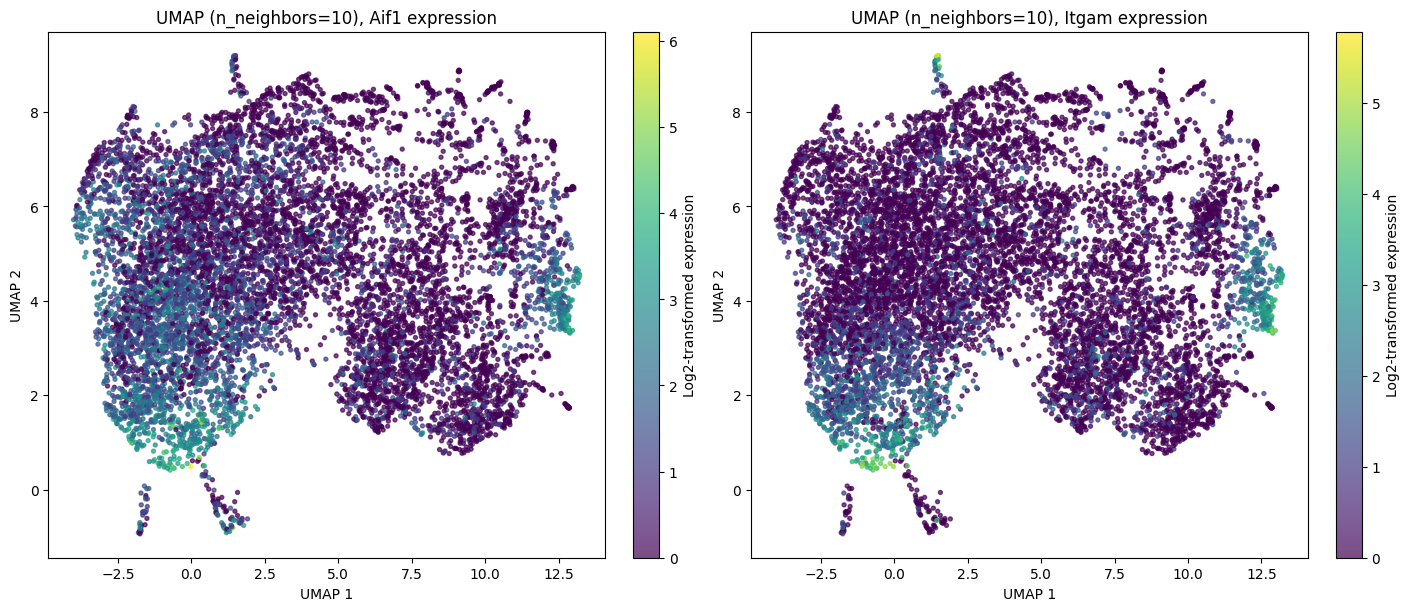

In [39]:
# Compute the UMAP embedding using n_neighbors=10
reducer_10 = umap.UMAP(
    n_neighbors=10,
    min_dist=0.3,
    n_components=2,
    metric="euclidean",
    random_state=42,
)
embedding_10 = reducer_10.fit_transform(log_counts)

# Plot UMAP colored by Aif1 and Itgam expression
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Aif1", "Itgam"]):
    scatter = ax.scatter(
        embedding_10[:, 0],
        embedding_10[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title(f"UMAP (n_neighbors=10), {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-transformed expression")

plt.show()

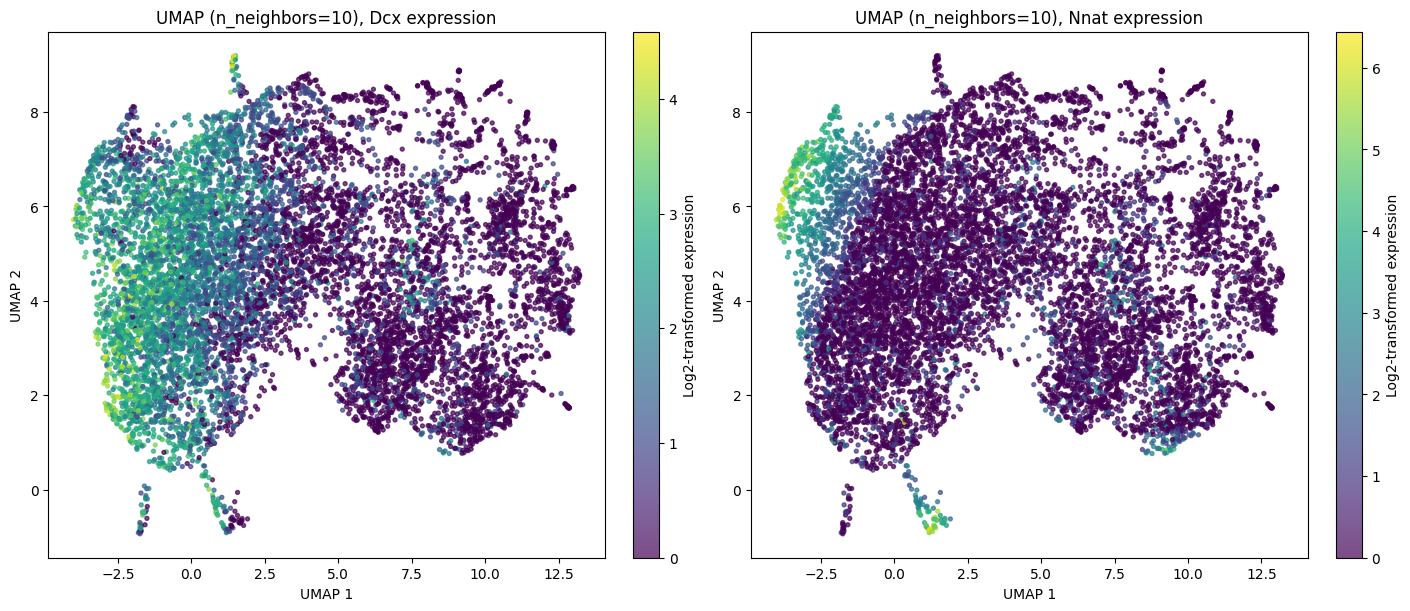

In [40]:
# Plot UMAP colored by marker gene expression
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Dcx", "Nnat"]):
    scatter = ax.scatter(
        embedding_10[:, 0],
        embedding_10[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title(f"UMAP (n_neighbors=10), {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-transformed expression")

plt.show()

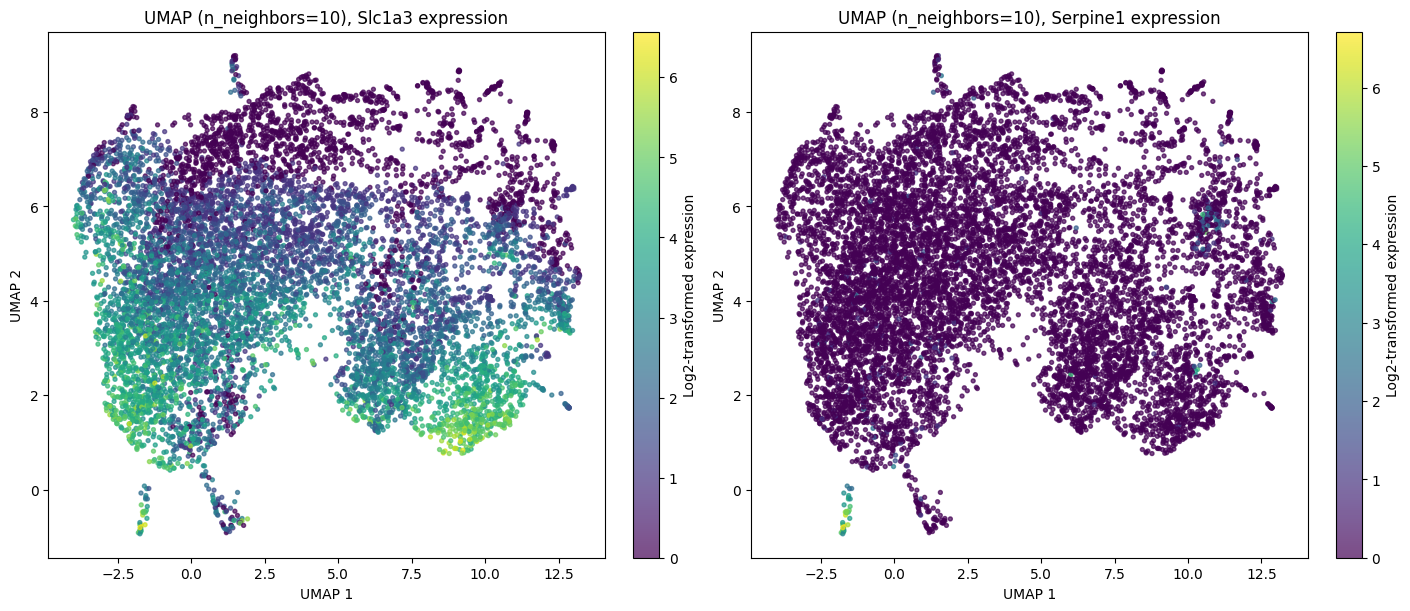

In [43]:
# Plot UMAP colored by marker gene expression
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, gene in zip(axes, ["Slc1a3", "Serpine1"]):
    scatter = ax.scatter(
        embedding_10[:, 0],
        embedding_10[:, 1],
        c=log_counts[gene],
        cmap="viridis",
        s=8,
        alpha=0.7,
    )
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title(f"UMAP (n_neighbors=10), {gene} expression")
    fig.colorbar(scatter, ax=ax, label="Log2-transformed expression")

plt.show()

# Finally, calling cell types

In [ ]:
marker_genes = {
    "Aif1": "microglia",
    "Itgam": "microglia",
    "Slc1a3": "astrocyte",
    "Dcx": "neural progenitor",
    "Nnat": "neural progenitor",
}

# Marker genes used by the classification rules
required_genes = list(marker_genes)

missing_genes = [
    gene for gene in required_genes
    if gene not in filtered_counts.columns
]

if missing_genes:
    raise ValueError(f"Missing marker genes: {missing_genes}")

marker_counts = filtered_counts[required_genes].astype(float)

## Microglia

In [48]:
# Rule 1:
# More than 10 counts of either Aif1 or Itgam
strong_microglia = (
    (marker_counts["Aif1"] > 5)
    | (marker_counts["Itgam"] > 5)
)

# Rule 2:
# At least 5 counts of both Aif1 and Itgam,
# and no more than 3 counts of any other marker gene
microglia_genes = ["Aif1", "Itgam"]
other_marker_genes = [
    gene for gene in required_genes
    if gene not in microglia_genes
]

both_microglia_markers = (
    (marker_counts["Aif1"] >= 3)
    & (marker_counts["Itgam"] >= 2)
)

low_other_markers = (
    marker_counts[other_marker_genes]
    .le(3)
    .all(axis=1)
)

moderate_microglia = both_microglia_markers 
# moderate_microglia = both_microglia_markers & low_other_markers

# Final microglia classification
is_microglia = strong_microglia | moderate_microglia

# Assign labels
cell_type = pd.Series("unclassified", index=filtered_counts.index)
cell_type.loc[is_microglia] = "microglia"

cell_type.value_counts()

unclassified    8734
microglia        877
Name: count, dtype: int64

In [49]:
strong_microglia.sum()

np.int64(600)

In [50]:
moderate_microglia.sum()

np.int64(601)

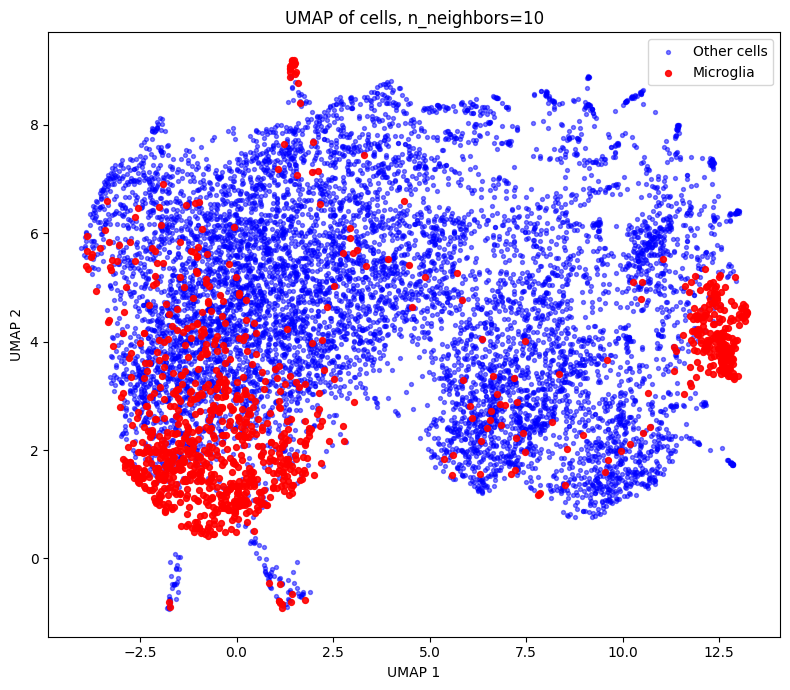

In [43]:
# Ensure the classification has the same row order as log_counts
is_microglia_aligned = is_microglia.loc[log_counts.index].to_numpy()

# Plot all cells first
plt.figure(figsize=(8, 7))

plt.scatter(
    embedding_10[~is_microglia_aligned, 0],
    embedding_10[~is_microglia_aligned, 1],
    s=8,
    c="blue",
    alpha=0.5,
    label="Other cells"
)

# Plot microglia on top
plt.scatter(
    embedding_10[is_microglia_aligned, 0],
    embedding_10[is_microglia_aligned, 1],
    s=18,
    c="red",
    alpha=0.9,
    label="Microglia"
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP of cells, n_neighbors=10")
plt.legend()
plt.tight_layout()
plt.show()

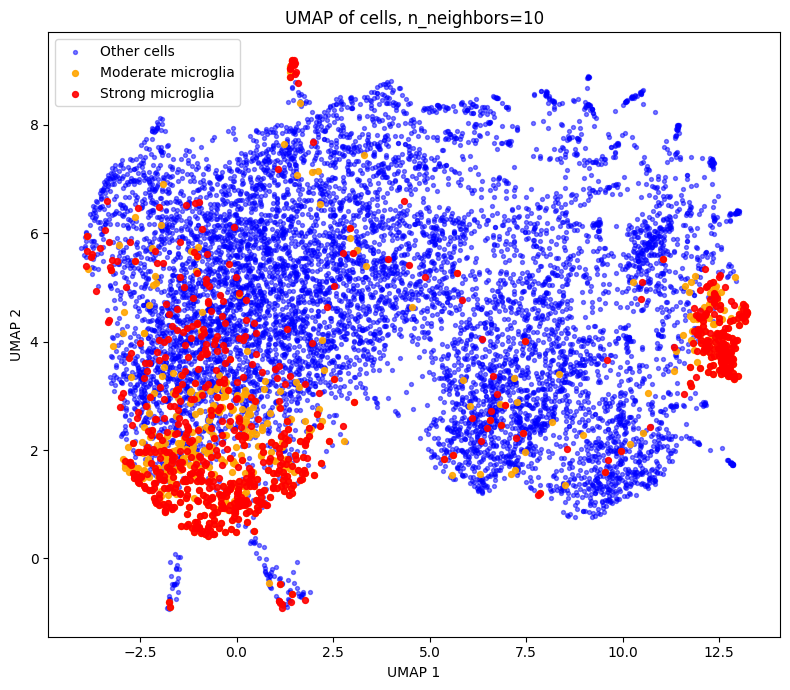

In [45]:
# Align the masks with the rows used to calculate embedding_10
strong_aligned = strong_microglia.loc[log_counts.index].to_numpy()
moderate_aligned = moderate_microglia.loc[log_counts.index].to_numpy()

# Optional consistency checks
assert len(embedding_10) == len(strong_aligned)
assert len(embedding_10) == len(moderate_aligned)

# Cells not belonging to either displayed group
other_cells = ~(strong_aligned | moderate_aligned)

plt.figure(figsize=(8, 7))

# Plot other cells first
plt.scatter(
    embedding_10[other_cells, 0],
    embedding_10[other_cells, 1],
    s=8,
    c="blue",
    alpha=0.5,
    label="Other cells"
)

# Plot moderate microglia
plt.scatter(
    embedding_10[moderate_aligned, 0],
    embedding_10[moderate_aligned, 1],
    s=18,
    c="orange",
    alpha=0.9,
    label="Moderate microglia"
)

# Plot strong microglia last
plt.scatter(
    embedding_10[strong_aligned, 0],
    embedding_10[strong_aligned, 1],
    s=18,
    c="red",
    alpha=0.9,
    label="Strong microglia"
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP of cells, n_neighbors=10")
plt.legend()
plt.tight_layout()
plt.show()

## Neural progenitor cells

In [53]:
# Rule 1:
# More than X counts of either Dcx or Nnat
strong_neural_progenitor = (
    (marker_counts["Dcx"] > 10)
    | (marker_counts["Nnat"] > 10)
)

# Rule 2:
# At least 5 counts of both Dcx and Nnat,
# and no more than 3 counts of any other marker gene
neural_progenitor_genes = ["Dcx", "Nnat"]
other_marker_genes = [
    gene for gene in required_genes
    if gene not in neural_progenitor_genes
]

both_neural_progenitor_markers = (
    (marker_counts["Dcx"] >= 5)
    & (marker_counts["Nnat"] >= 5)
)

# low_other_markers = (
#     marker_counts[other_marker_genes]
#     .le(3)
#     .all(axis=1)
# )

moderate_neural_progenitor= both_neural_progenitor_markers 
# moderate_neural_progenitor = both_neural_progenitor_markers & low_other_markers

# Final neural_progenitor classification
is_neural_progenitor = strong_neural_progenitor | moderate_neural_progenitor

# Assign labels
cell_type = pd.Series("unclassified", index=filtered_counts.index)
cell_type.loc[is_neural_progenitor] = "neural_progenitor"

cell_type.value_counts()

unclassified         9110
neural_progenitor     501
Name: count, dtype: int64

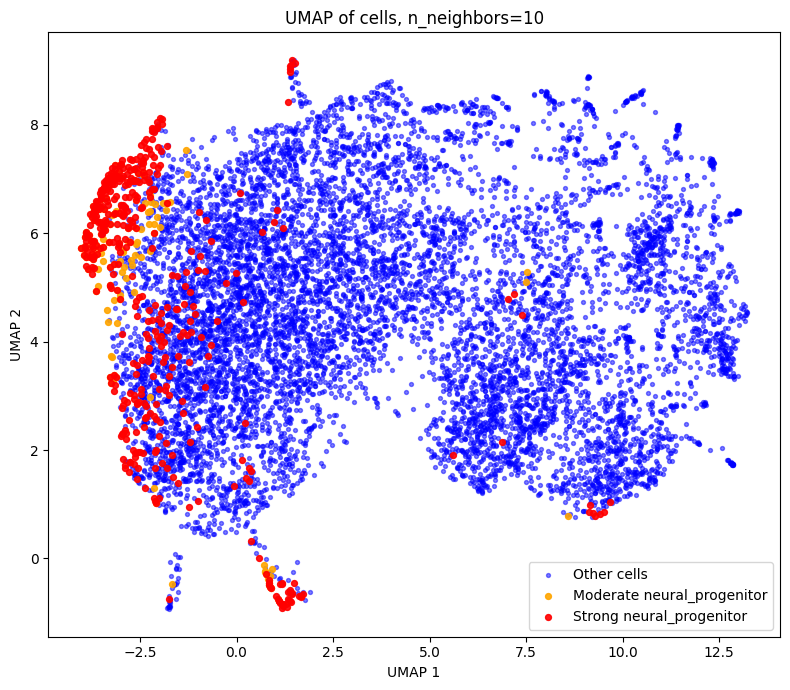

In [57]:
# Align the masks with the rows used to calculate embedding_10
strong_aligned_np = strong_neural_progenitor.loc[log_counts.index].to_numpy()
moderate_aligned_np = moderate_neural_progenitor.loc[log_counts.index].to_numpy()

# Optional consistency checks
assert len(embedding_10) == len(strong_aligned_np)
assert len(embedding_10) == len(moderate_aligned_np)

# Cells not belonging to either displayed group
other_cells = ~(strong_aligned_np | moderate_aligned_np)

plt.figure(figsize=(8, 7))

# Plot other cells first
plt.scatter(
    embedding_10[other_cells, 0],
    embedding_10[other_cells, 1],
    s=8,
    c="blue",
    alpha=0.5,
    label="Other cells"
)

# Plot moderate neural_progenitor
plt.scatter(
    embedding_10[moderate_aligned_np, 0],
    embedding_10[moderate_aligned_np, 1],
    s=18,
    c="orange",
    alpha=0.9,
    label="Moderate neural_progenitor"
)

# Plot strong neural_progenitor last
plt.scatter(
    embedding_10[strong_aligned_np, 0],
    embedding_10[strong_aligned_np, 1],
    s=18,
    c="red",
    alpha=0.9,
    label="Strong neural_progenitor"
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP of cells, n_neighbors=10")
plt.legend()
plt.tight_layout()
plt.show()

## Astrocytes

In [58]:
is_astrocyte = (
    (marker_counts["Slc1a3"] > 10)
    & marker_counts[["Aif1", "Itgam", "Dcx", "Nnat"]].le(3).all(axis=1)
)

In [61]:
is_astrocyte.sum()

np.int64(833)

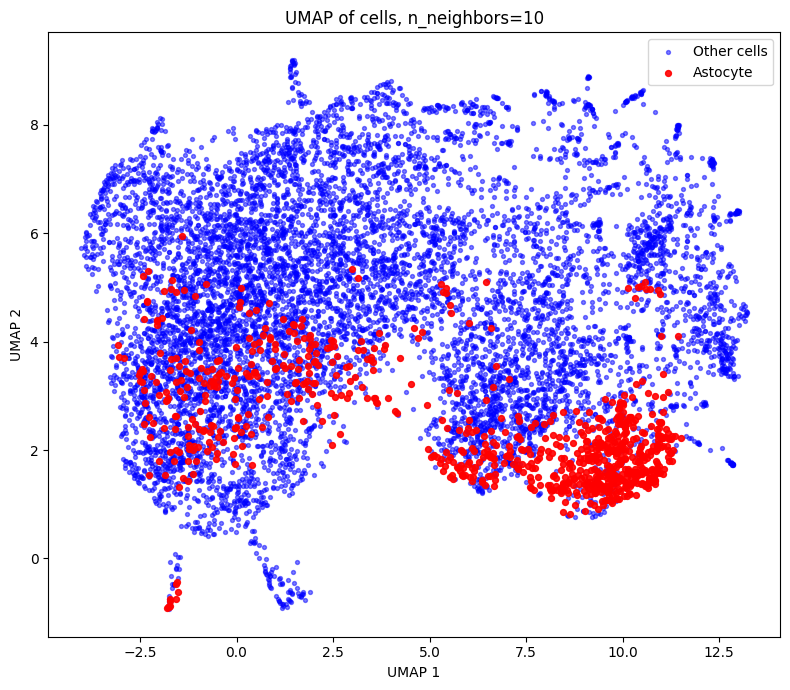

In [63]:
# Cells not belonging to either displayed group
other_cells = ~(is_astrocyte)

plt.figure(figsize=(8, 7))

# Plot other cells first
plt.scatter(
    embedding_10[other_cells, 0],
    embedding_10[other_cells, 1],
    s=8,
    c="blue",
    alpha=0.5,
    label="Other cells"
)

# Plot astrocytes
plt.scatter(
    embedding_10[is_astrocyte, 0],
    embedding_10[is_astrocyte, 1],
    s=18,
    c="red",
    alpha=0.9,
    label="Astocyte"
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP of cells, n_neighbors=10")
plt.legend()
plt.tight_layout()
plt.show()

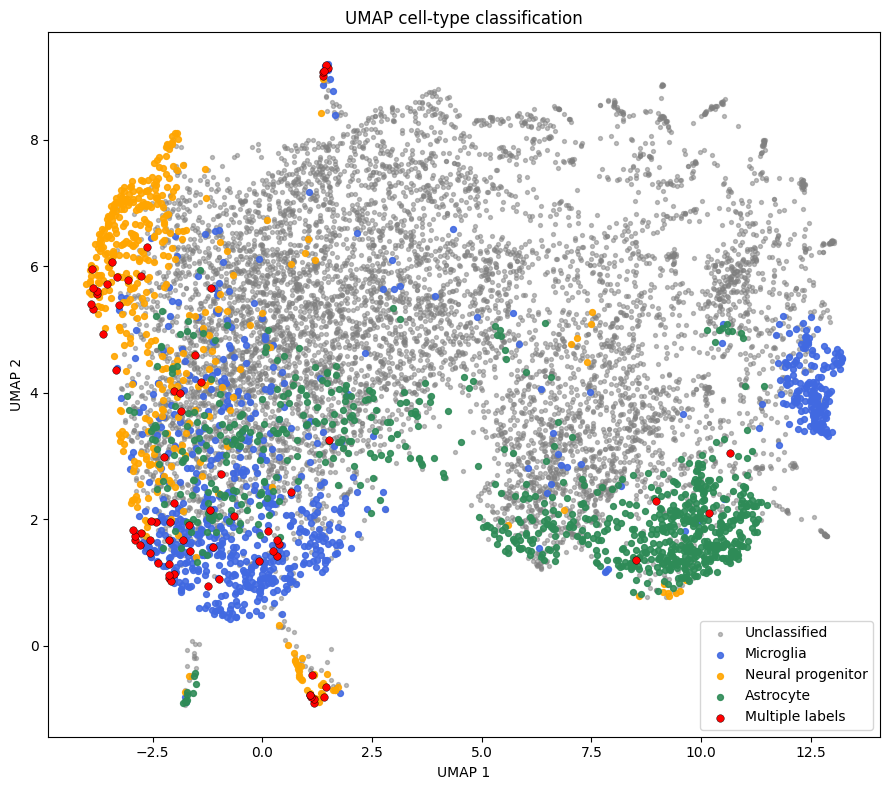

Unclassified: 7474
Microglia: 803
Neural progenitor: 436
Astrocyte: 824
Multiple labels: 74


In [65]:
# Combine strong and moderate calls into one mask for each cell type
microglia_mask = (
    strong_microglia | moderate_microglia
).reindex(log_counts.index, fill_value=False).to_numpy()

neural_progenitor_mask = (
    strong_neural_progenitor | moderate_neural_progenitor
).reindex(log_counts.index, fill_value=False).to_numpy()

astrocyte_mask = is_astrocyte.reindex(
    log_counts.index, fill_value=False
).to_numpy()

# Count the number of cell-type labels per cell
label_count = (
    microglia_mask.astype(int)
    + neural_progenitor_mask.astype(int)
    + astrocyte_mask.astype(int)
)

overlap_mask = label_count > 1
microglia_only = microglia_mask & (label_count == 1)
neural_progenitor_only = neural_progenitor_mask & (label_count == 1)
astrocyte_only = astrocyte_mask & (label_count == 1)
unclassified = label_count == 0

plt.figure(figsize=(9, 8))

plt.scatter(
    embedding_10[unclassified, 0],
    embedding_10[unclassified, 1],
    s=8,
    c="gray",
    alpha=0.5,
    label="Unclassified",
)

plt.scatter(
    embedding_10[microglia_only, 0],
    embedding_10[microglia_only, 1],
    s=18,
    c="royalblue",
    alpha=0.9,
    label="Microglia",
)

plt.scatter(
    embedding_10[neural_progenitor_only, 0],
    embedding_10[neural_progenitor_only, 1],
    s=18,
    c="orange",
    alpha=0.9,
    label="Neural progenitor",
)

plt.scatter(
    embedding_10[astrocyte_only, 0],
    embedding_10[astrocyte_only, 1],
    s=18,
    c="seagreen",
    alpha=0.9,
    label="Astrocyte",
)

plt.scatter(
    embedding_10[overlap_mask, 0],
    embedding_10[overlap_mask, 1],
    s=30,
    c="red",
    edgecolors="black",
    linewidths=0.3,
    alpha=1,
    label="Multiple labels",
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP cell-type classification")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Unclassified: {unclassified.sum()}")
print(f"Microglia: {microglia_only.sum()}")
print(f"Neural progenitor: {neural_progenitor_only.sum()}")
print(f"Astrocyte: {astrocyte_only.sum()}")
print(f"Multiple labels: {overlap_mask.sum()}")